In [1]:
import os
import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

c:\Users\jason\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

# Load

In [3]:
data_path = "../artifacts/processed_data.pkl"
assert os.path.exists(data_path), f"Không tìm thấy file tại {data_path}!"

data = joblib.load(data_path)

X_train = data["X_train_res"]
X_test  = data["X_test_scaled"]
y_test  = data["y_test"]
feature_names = data["feature_names"]

if not isinstance(X_train, pd.DataFrame):
    X_train_df = pd.DataFrame(X_train, columns=feature_names)
else:
    X_train_df = X_train.copy()

if not isinstance(X_test, pd.DataFrame):
    X_test_df = pd.DataFrame(X_test, columns=feature_names)
else:
    X_test_df = X_test.copy()

print(f"-> Nạp dữ liệu thành công:")
print(f"   X_train : {X_train_df.shape}")
print(f"   X_test  : {X_test_df.shape}")
print(f"   Số lượng đặc trưng: {len(feature_names)}")

-> Nạp dữ liệu thành công:
   X_train : (42732, 16)
   X_test  : (29538, 16)
   Số lượng đặc trưng: 16


In [4]:
artifacts_dir = "../artifacts"

log_model = joblib.load(os.path.join(artifacts_dir, "logistic_model.pkl"))
dt_model  = joblib.load(os.path.join(artifacts_dir, "decision_tree_model.pkl"))
rf_model  = joblib.load(os.path.join(artifacts_dir, "random_forest_model.pkl"))
xgb_model = joblib.load(os.path.join(artifacts_dir, "xgboost_model.pkl"))

log_info = joblib.load(os.path.join(artifacts_dir, "logistic_info.pkl"))
dt_info  = joblib.load(os.path.join(artifacts_dir, "decision_tree_info.pkl"))
rf_info  = joblib.load(os.path.join(artifacts_dir, "random_forest_info.pkl"))
xgb_info = joblib.load(os.path.join(artifacts_dir, "xgboost_info.pkl"))

print("-> Đã nạp thành công cả 4 mô hình:")
print(f"   1. Logistic Regression (Best Threshold = {log_info['best_threshold']:.2f})")
print(f"   2. Decision Tree       (Best Threshold = {dt_info['best_threshold']:.2f})")
print(f"   3. Random Forest       (Best Threshold = {rf_info['best_threshold']:.2f})")
print(f"   4. XGBoost             (Best Threshold = {xgb_info['best_threshold']:.2f})")

-> Đã nạp thành công cả 4 mô hình:
   1. Logistic Regression (Best Threshold = 0.70)
   2. Decision Tree       (Best Threshold = 0.66)
   3. Random Forest       (Best Threshold = 0.63)
   4. XGBoost             (Best Threshold = 0.61)


# Plot

In [5]:
def plot_shap_summary_and_bar(shap_values, X_sample, model_name, max_display=12):
    plt.figure(figsize=(10, 6))
    plt.title(f"SHAP Beeswarm Summary Plot - {model_name}", fontsize=13, pad=12)
    shap.plots.beeswarm(shap_values, max_display=max_display, show=False)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(9, 5))
    plt.title(f"SHAP Feature Importance (Bar) - {model_name}", fontsize=13, pad=12)
    shap.plots.bar(shap_values, max_display=max_display, show=False)
    plt.tight_layout()
    plt.show()

def plot_shap_local_waterfall(shap_values, sample_idx=0, model_name="Model", max_display=10):
    """Vẽ biểu đồ Local: Waterfall plot giải thích cho 1 khách hàng cụ thể"""
    plt.figure(figsize=(9, 5.5))
    plt.title(f"SHAP Local Waterfall Plot (User Index = {sample_idx}) - {model_name}", fontsize=13, pad=12)
    shap.plots.waterfall(shap_values[sample_idx], max_display=max_display, show=False)
    plt.tight_layout()
    plt.show()

# Logistic Regression

Background dataset has 500 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=500 when initializing the masker.


1. PHÂN TÍCH SHAP: LOGISTIC REGRESSION


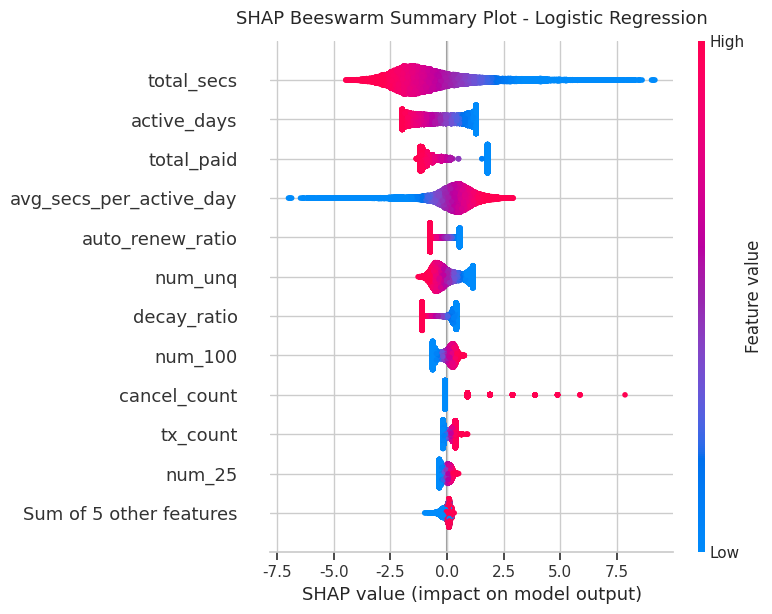

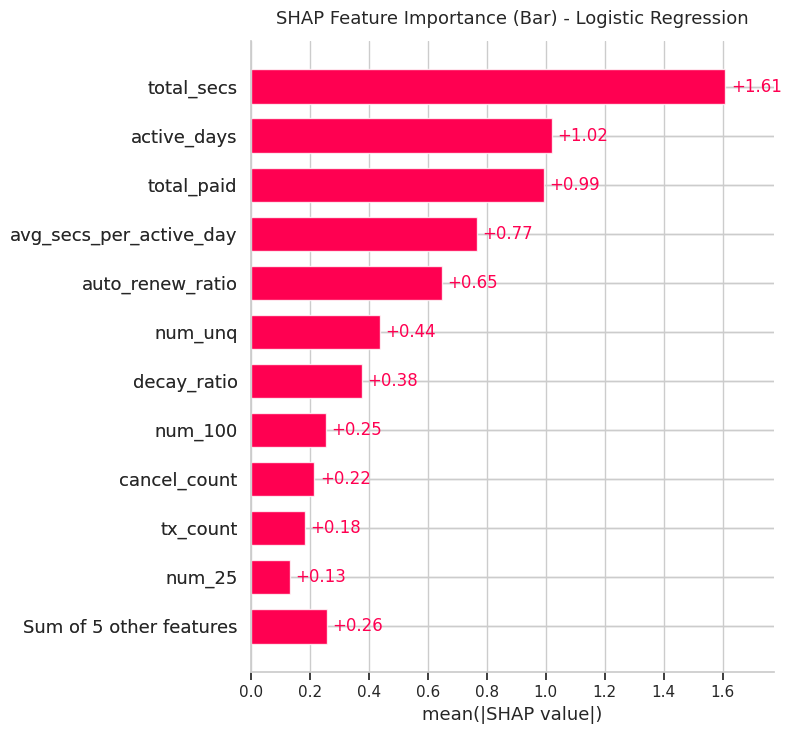

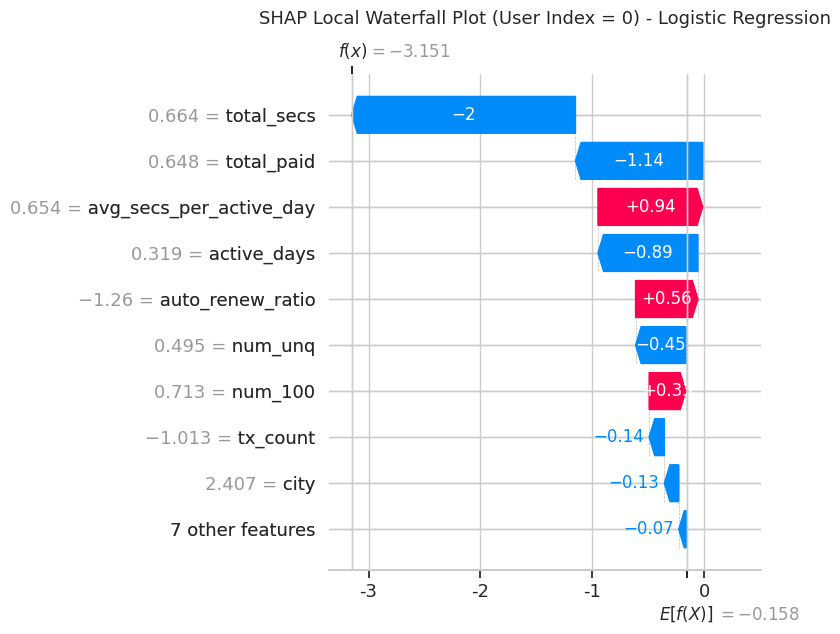

In [6]:
print("1. PHÂN TÍCH SHAP: LOGISTIC REGRESSION")

background_sample = shap.maskers.Independent(X_train_df.sample(n=min(500, len(X_train_df)), random_state=42))

# Khởi tạo LinearExplainer
explainer_log = shap.LinearExplainer(log_model, masker=background_sample)
shap_values_log = explainer_log(X_test_df)
shap_values_log.feature_names = list(feature_names)

# Trực quan hóa Global & Local
plot_shap_summary_and_bar(shap_values_log, X_test_df, model_name="Logistic Regression")
plot_shap_local_waterfall(shap_values_log, sample_idx=0, model_name="Logistic Regression")

# Decision Tree

2. PHÂN TÍCH SHAP: DECISION TREE


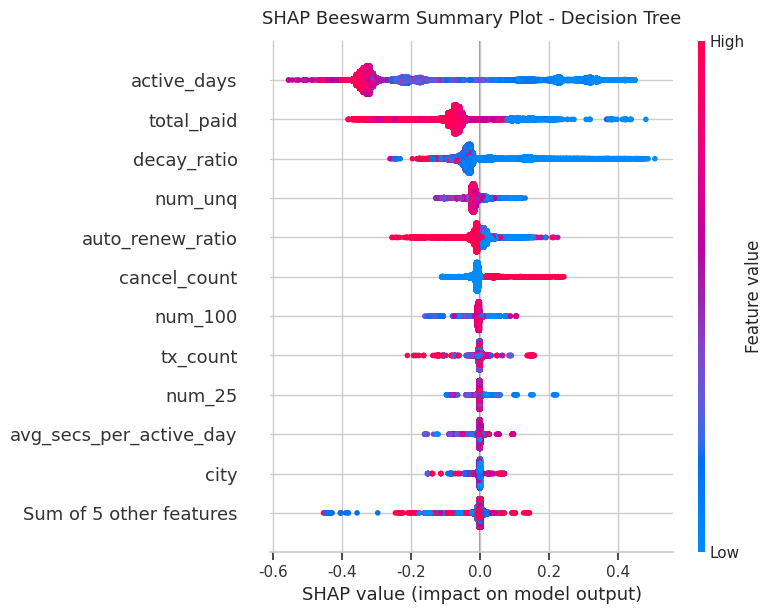

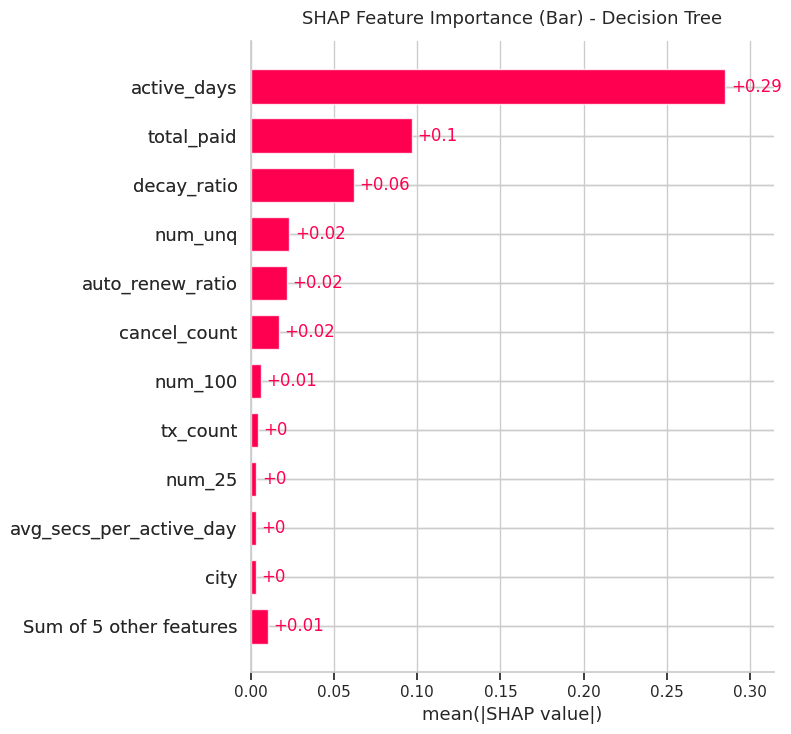

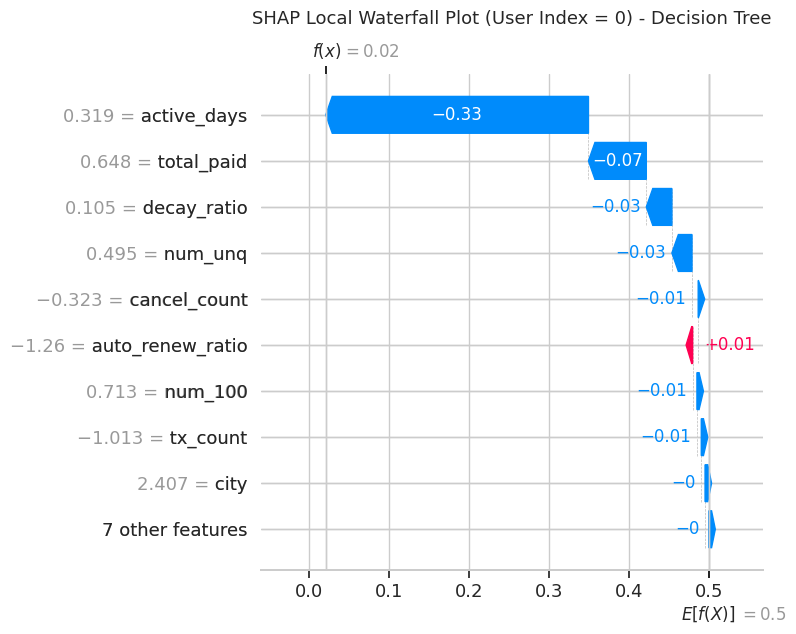

In [7]:
print("2. PHÂN TÍCH SHAP: DECISION TREE")

explainer_dt = shap.TreeExplainer(dt_model)
shap_explanation_dt = explainer_dt(X_test_df)

if len(shap_explanation_dt.shape) == 3 and shap_explanation_dt.shape[-1] == 2:
    shap_values_dt = shap_explanation_dt[..., 1]
else:
    shap_values_dt = shap_explanation_dt
shap_values_dt.feature_names = list(feature_names)

plot_shap_summary_and_bar(shap_values_dt, X_test_df, model_name="Decision Tree")
plot_shap_local_waterfall(shap_values_dt, sample_idx=0, model_name="Decision Tree")

# Random Forest

In [ ]:
print("3. PHÂN TÍCH SHAP: RANDOM FOREST")

explainer_rf = shap.TreeExplainer(rf_model)
shap_explanation_rf = explainer_rf(X_test_df)

if len(shap_explanation_rf.shape) == 3 and shap_explanation_rf.shape[-1] == 2:
    shap_values_rf = shap_explanation_rf[..., 1]
else:
    shap_values_rf = shap_explanation_rf
shap_values_rf.feature_names = list(feature_names)

plot_shap_summary_and_bar(shap_values_rf, X_test_df, model_name="Random Forest")
plot_shap_local_waterfall(shap_values_rf, sample_idx=0, model_name="Random Forest")

# XGBoost

4. PHÂN TÍCH SHAP: XGBOOST


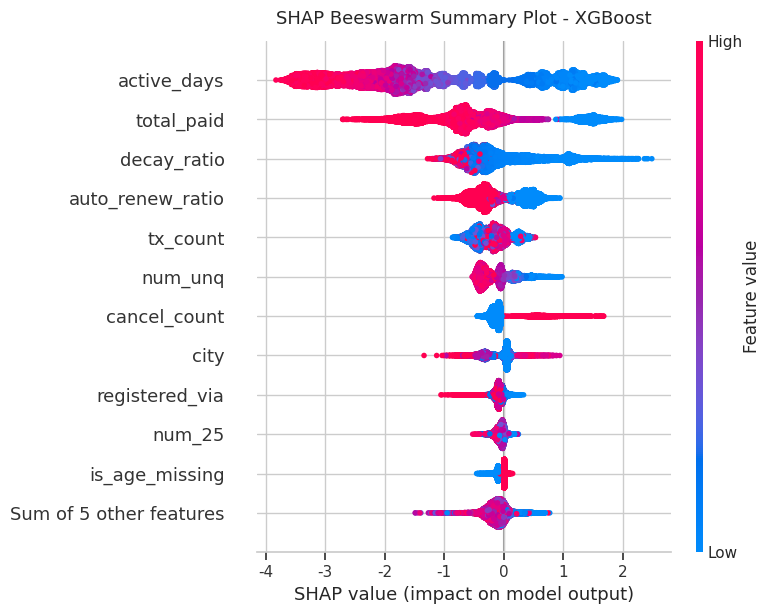

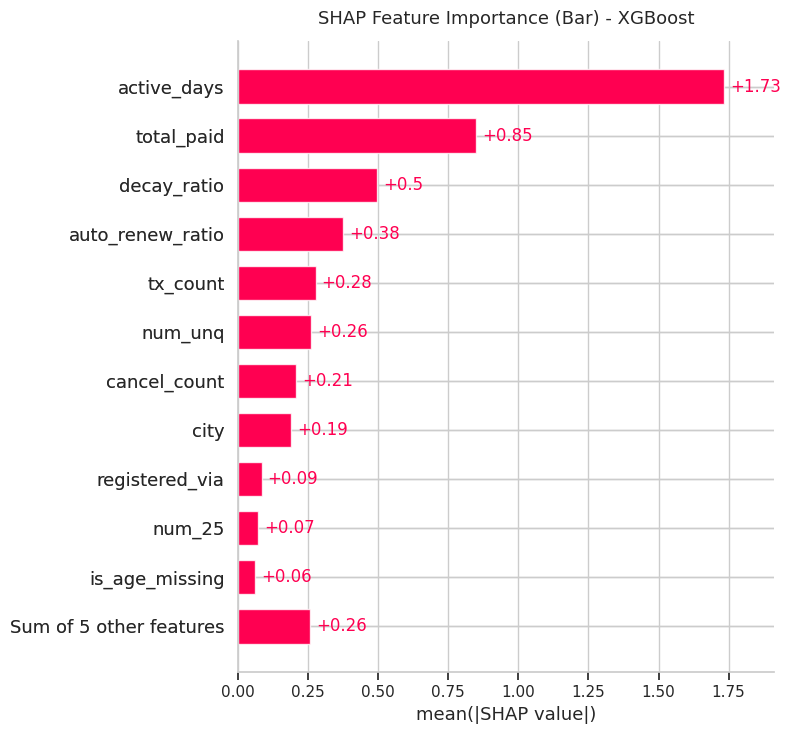

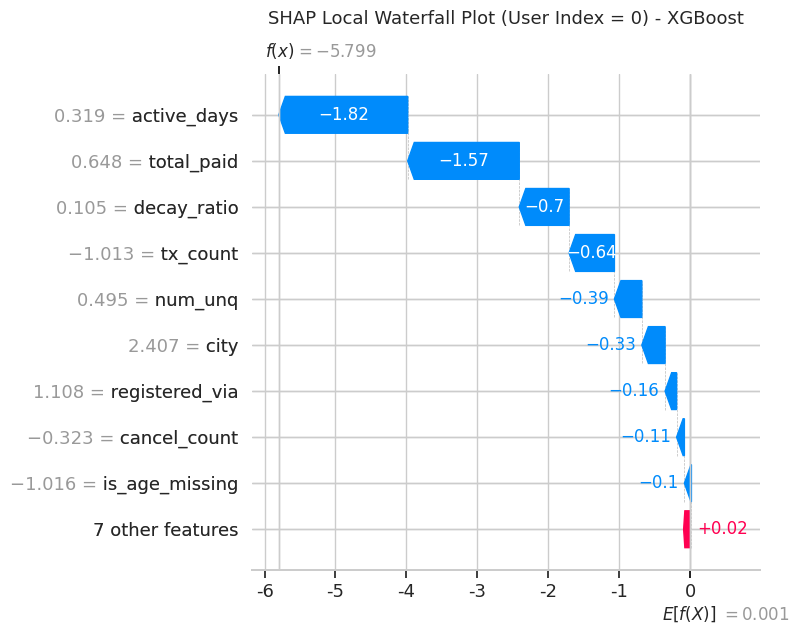

In [8]:
print("4. PHÂN TÍCH SHAP: XGBOOST")

explainer_xgb = shap.TreeExplainer(xgb_model)
shap_explanation_xgb = explainer_xgb(X_test_df)

if len(shap_explanation_xgb.shape) == 3 and shap_explanation_xgb.shape[-1] == 2:
    shap_values_xgb = shap_explanation_xgb[..., 1]
else:
    shap_values_xgb = shap_explanation_xgb
shap_values_xgb.feature_names = list(feature_names)

plot_shap_summary_and_bar(shap_values_xgb, X_test_df, model_name="XGBoost")
plot_shap_local_waterfall(shap_values_xgb, sample_idx=0, model_name="XGBoost")

# COMPARISON

In [ ]:
def get_mean_abs_shap_df(shap_vals, model_name):
    mean_abs = np.abs(shap_vals.values).mean(axis=0)
    return pd.DataFrame({"feature": feature_names, model_name: mean_abs})

df_imp_log = get_mean_abs_shap_df(shap_values_log, "Logistic Regression")
df_imp_dt  = get_mean_abs_shap_df(shap_values_dt, "Decision Tree")
df_imp_rf  = get_mean_abs_shap_df(shap_values_rf, "Random Forest")
df_imp_xgb = get_mean_abs_shap_df(shap_values_xgb, "XGBoost")

df_compare_shap = df_imp_xgb.merge(df_imp_rf, on="feature") \
                            .merge(df_imp_dt, on="feature") \
                            .merge(df_imp_log, on="feature")

df_compare_shap = df_compare_shap.sort_values(by="XGBoost", ascending=False).reset_index(drop=True)

print("\nBẢNG SO SÁNH GIÁ TRỊ TRUNG BÌNH |SHAP| CỦA 16 ĐẶC TRƯNG")
display(df_compare_shap)


BẢNG SO SÁNH GIÁ TRỊ TRUNG BÌNH |SHAP| CỦA 16 ĐẶC TRƯNG


,feature,XGBoost,Random Forest,Decision Tree,Logistic Regression
0,active_days,1.278770,0.108852,0.279315,1.078199
1,tx_count,1.103999,0.073964,0.101825,0.637921
2,decay_ratio,0.890139,0.075605,0.097482,0.727592
3,total_paid,0.269788,0.030879,0.012545,0.436530
4,auto_renew_ratio,0.254530,0.084537,0.012179,0.637921
5,num_unq,0.212013,0.056763,0.006397,0.479781
6,city,0.176675,0.006937,0.001701,0.031412
7,num_25,0.114912,0.014011,0.006504,0.236454
8,num_100,0.095235,0.029720,0.009501,0.298580
9,registered_via,0.084741,0.015692,0.006620,0.107584


In [9]:
best_model_name = "xgboost"
best_explainer = explainer_xgb

save_explainer_path = os.path.join(artifacts_dir, "best_shap_explainer.pkl")
joblib.dump(best_explainer, save_explainer_path)

print(f"-> Đã đóng gói thành công {best_model_name.upper()} Explainer tại: {save_explainer_path}")

-> Đã đóng gói thành công XGBOOST Explainer tại: ../artifacts\best_shap_explainer.pkl
